# **Installation and Libraries**
---
The analysis requires the **jenkspy** library, which is not installed by default in the runtime environment. This library implements the Fisher-Jenks natural breaks algorithm, which is used later to classify the number of transactions and active quarters into low, medium, and high categories without relying on manually defined thresholds.

In [ ]:
# Installations
# ==============================================================================
!pip install jenkspy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 638.1/638.1 kB 6.4 MB/s  0:00:00


The libraries used throughout the workflow are imported and organized by function.

In [ ]:
# Utils
# ==============================================================================
import warnings
from typing import Optional
from unicodedata import normalize

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Data
# ==============================================================================
import pandas as pd
import numpy as np
import jenkspy

# Model
# ==============================================================================
from sklearn.ensemble import IsolationForest

# **Info**
---
**@By**: Steven Bernal

**@Nickname:** Kaiziferr

**@Git**: https://github.com/Kaiziferr

# **Configuration**
---

This section defines the global variables and display settings used throughout the analysis.

The configuration includes the following components:

- **Random seed:** the value `12354` is set so that the Isolation Forest model produces the same results in every run.
- **Warning management:** warning messages are suppressed to keep the outputs clean.
- **Chart style:** the Seaborn darkgrid style is applied as the default theme.
- **DataFrame formatting:** decimal values are displayed with two decimal places and commas as thousands separators.
- **Color palette:** a fixed color is assigned to each payment type (royalties and compensation payments), to each model class (-1 for anomalies and 1 for normal records), and to each category (Low, Medium, and High). As a result, colors keep the same meaning in all charts.
- **NumPy formatting:** arrays are displayed with three decimal places and without scientific notation when possible.
- **Value translation:** the language_change dictionary is defined to convert the original Spanish payment types (REGALIAS and COMPENSACIÓN) into standardized English labels.

In [ ]:
random_seed = 12354
warnings.filterwarnings('ignore')
sns.set(style='darkgrid')
pd.set_option('display.float_format', '{:,.2f}'.format)

paleta = {
    'ROYALTY_PAYMENTS': '#E9C46A',
    'COMPENSATION_PAYMENTS': '#D946A8',
    "-1": '#FF5733',
    "1": '#2ECC71',
    "Low": '#00A6A6',
    "Medium": '#9D4EDD',
    "High": '#0077B6'
}

np.set_printoptions(precision=3, suppress=True)


language_change = {'REGALIAS':'ROYALTY_PAYMENTS',
 'COMPENSACIÓN':'COMPENSATION_PAYMENTS'
}

# **Context**
---

The dataset contains information on mining activity in Colombia. Each mining project generates **royalty** and **compensation** payments to the corresponding producing municipality. The data is in Spanish and includes the municipality, department, natural resource, project name, production year and quarter, unit of measure, payment type, payment amount, and production quantity.

The dataset is used to apply the **Isolation Forest** algorithm to anomaly detection. This algorithm is unsupervised: it does not require labeled examples of normal or anomalous behavior. For this reason, its results identify records that are unusual compared with the rest of the data, but they do not confirm the existence of errors or irregularities on their own.

# **Goal**
---

Identify anomalous records based on multivariate patterns in royalty and compensation payments associated with mining projects, using the Isolation Forest algorithm.

The analysis considers three dimensions for each municipality during the 2018 to 2022 period: the **total amount paid**, the **number of transactions**, and the **number of active quarters**. A record is considered anomalous when it shows unusual behavior in one or more of the three dimensions, either individually or through a combination that deviates from the general pattern of its group.

# **Helper Functions**
---

This section defines two reusable functions that support data preparation and exploration:

- **normalize_word():** converts a text into lowercase snake_case without accent marks. It replaces spaces and hyphens with underscores, removes repeated separators, and applies Unicode NFKD normalization with ASCII conversion. It is used to standardize the column names of the original file, which are in Spanish and contain accent marks and spaces.
- **plot_3d_scatter():** creates an interactive 3D scatter plot with Plotly. Before plotting, it validates that the columns exist, that the axes are numeric and finite, and that the visual parameters are valid. It allows the color and symbol of the points to be assigned according to a variable, which makes it easier to compare payment types and model classes in the same chart.

In [ ]:
def normalize_word(word:str)->str:
  """
    Normalize a string into a standardized snake_case format.

    This function converts a word or phrase into a normalized representation
    suitable for use as column names, identifiers, or feature names. The
    normalization process performs the following operations:

    1. Replaces spaces (`" "`) with underscores (`"_"`).
    2. Replaces hyphens (`"-"`) with underscores (`"_"`).
    3. Removes consecutive or leading/trailing underscores generated during
      the replacement process.
    4. Converts all characters to lowercase.
    5. Removes diacritical marks (accents) by converting Unicode characters
      to their closest ASCII representation.
    6. Joins the resulting tokens using a single underscore.

    Parameters
    ----------
    word : str
        Input string to normalize.

    Returns
    -------
    str
        A normalized string in lowercase snake_case with ASCII characters
        only.
  """
  word = word.replace(' ', '_')
  word = word.replace('-', '_')
  find_guion = word.find('_')
  list_word = []
  if find_guion:
    list_word = [w for w in word.split('_') if w != '']
  else:
    list_word = word
  word = list(map(lambda x: x.lower(), list_word))
  word = [normalize('NFKD', c).encode('ASCII', 'ignore').decode() for c in word]
  word = "_".join(word)
  return word


def plot_3d_scatter(
    data: pd.DataFrame,
    *,
    x: str,
    y: str,
    z: str,
    color: Optional[str] = None,
    color_map: Optional[dict] = None,
    symbol: Optional[str] = None,
    size: Optional[str] = None,
    title: str = "3D Scatter Plot",
    point_size: float = 5.0,
    opacity: float = 0.85,
    height: int = 750,
    show: bool = True,
) -> go.Figure:
    """Create an interactive 3D scatter plot with optional visual encodings."""

    axes = (x, y, z)
    visual_features = (color, symbol, size)

    required_columns = list(dict.fromkeys(
        [
            *axes,
            *(feature for feature in visual_features
              if feature is not None),
        ]
    ))

    if data.empty:
        raise ValueError("'data' cannot be empty.")

    missing_columns = set(required_columns) - set(data.columns)
    if missing_columns:
        raise ValueError(f"Missing columns: {sorted(missing_columns)}")

    if len(set(axes)) != 3:
        raise ValueError(
            "The x, y, and z axes must use distinct columns."
        )

    for axis in axes:
        if not pd.api.types.is_numeric_dtype(data[axis]):
            raise TypeError(f"Axis '{axis}' must be numeric.")

        values = data[axis].to_numpy(dtype=float)

        if not np.isfinite(values).all():
            raise ValueError(
                f"Axis '{axis}' contains null or non-finite values."
            )

    if size is not None:
        if not pd.api.types.is_numeric_dtype(data[size]):
            raise TypeError(f"Size feature '{size}' must be numeric.")

        size_values = data[size].to_numpy(dtype=float)

        if (
            not np.isfinite(size_values).all()
            or (size_values < 0).any()
        ):
            raise ValueError(
                f"Size feature '{size}' must contain finite, "
                "non-negative values."
            )

    if not np.isfinite([point_size, opacity]).all():
        raise ValueError(
            "'point_size' and 'opacity' must be finite."
        )

    if point_size <= 0:
        raise ValueError("'point_size' must be greater than zero.")

    if not 0 < opacity <= 1:
        raise ValueError(
            "'opacity' must be in the interval (0, 1]."
        )

    if height < 300:
        raise ValueError("'height' must be at least 300 pixels.")

    plot_data = data.loc[:, required_columns].copy()

    figure = px.scatter_3d(
        data_frame=plot_data,
        x=x,
        y=y,
        z=z,
        color=color,
        symbol=symbol,
        size=size,
        title=title,
        opacity=opacity,
        template="plotly_white",
        height=height,
        size_max=18,
        color_discrete_sequence=px.colors.qualitative.Bold,
        color_discrete_map=color_map or {},
        labels={
            feature: feature.replace("_", " ").title()
            for feature in required_columns
        },
    )

    figure.update_traces(
        marker={
            "line": {"width": 0.5, "color": "white"},
        },
        selector={"type": "scatter3d"},
    )

    if size is None:
        figure.update_traces(marker_size=point_size)

    figure.update_layout(
        scene={
            "aspectmode": "cube",
            "xaxis": {
                "showbackground": False,
                "showgrid": True,
            },
            "yaxis": {
                "showbackground": False,
                "showgrid": True,
            },
            "zaxis": {
                "showbackground": False,
                "showgrid": True,
            },
            "camera": {
                "eye": {"x": 1.6, "y": 1.6, "z": 1.3}
            },
        },
        legend_title_text="Visual Categories",
        margin={"l": 0, "r": 0, "t": 65, "b": 0},
    )

    if show:
        figure.show()

    return figure

# **Data**
---

The dataset is loaded from a CSV file stored in Google Drive. The shared URL is converted into a direct download link based on the file identifier.

All columns are read as text (dtype='str'). In this way, data types are assigned explicitly in the following steps, which prevents incorrect automatic conversions in fields such as the quarter or the payment amount.

In [ ]:
url_mining_materials = 'https://drive.google.com/file/d/10_YGM_dOKzzLsLNkfB_bN5YeLgDHcrUZ/view?usp=sharing'
url_mining_materials = 'https://drive.google.com/uc?id=' + url_mining_materials.split('/')[-2]
mineral_extraction_data = pd.read_csv(url_mining_materials, dtype='str')

The column names are standardized and translated from Spanish into English to improve the consistency and readability of the analysis.

The following operations are performed:

- **Normalization:** the normalize_word() function is applied to each column name to remove accent marks, spaces, and uppercase letters.
- **Translation:** a dictionary maps each normalized Spanish name to its English equivalent. For example, valor_contraprestacion becomes payment_amount and tipo_contraprestacion becomes payment_type.
- **Name preservation:** columns without an entry in the dictionary keep their normalized name.
- **Assignment:** the resulting names replace the original names in the DataFrame.

In [ ]:
data_names_traslator = mineral_extraction_data.columns.map(
    lambda x: normalize_word(x)
)

column_translation = {
    'municipio_productor': 'producing_municipality',
    'departamento': 'department',
    'recurso_natural': 'natural_resource',
    'nombre_del_proyecto': 'project_name',
    'ano_produccion': 'production_year',
    'trimestre': 'quarter',
    'unidad_medida': 'unit_of_measure',
    'tipo_contraprestacion': 'payment_type',
    'valor_contraprestacion': 'payment_amount',
    'cantidad_produccion': 'production_quantity'
}

data_names_traslator = data_names_traslator.map(
    lambda x: column_translation[x] if x in column_translation.keys() else x
)

data_names_traslator
mineral_extraction_data.columns = data_names_traslator

The values in the payment_type column are translated from Spanish into English using the language_change dictionary defined in the configuration:

- **REGALIAS** is replaced with **ROYALTY_PAYMENTS**.
- **COMPENSACIÓN** is replaced with **COMPENSATION_PAYMENTS**.

With this step, payment categories use standardized labels throughout the analysis. These labels are also the keys of the color palette, so each payment type keeps its color in the charts.

In [ ]:
mineral_extraction_data['payment_type'] = mineral_extraction_data['payment_type'].map(
    lambda x: language_change[x]
)

The payment_amount and production_quantity columns are converted from text to decimal numeric values (float64). This conversion is required to calculate sums and other numerical operations in the aggregation stages.

In [ ]:
mineral_extraction_data[[
    'payment_amount',
    'production_quantity'
]] = mineral_extraction_data[[
    'payment_amount',
    'production_quantity'
]].astype('float64')

The quarter column originally contains text. The code splits this text by spaces and keeps the second element, which corresponds to the quarter number. In this way, the quarter can later be treated as a numeric variable.

In [ ]:
mineral_extraction_data[
    'quarter'] = mineral_extraction_data[
        'quarter'].apply(lambda x: x.split(' ')[1])

mineral_extraction_data.head(3)

,producing_municipality,department,natural_resource,project_name,production_year,quarter,unit_of_measure,payment_type,payment_amount,production_quantity
0,Medellin,Antioquia,ARCILLAS,PRODUCTORES,2018,4,TONELADAS,ROYALTY_PAYMENTS,"614,258.00",0.00
1,Medellin,Antioquia,ARCILLAS CERAMICAS,PRODUCTORES,2014,4,TONELADAS,ROYALTY_PAYMENTS,"2,036,781.00","14,381.00"
2,Medellin,Antioquia,ARCILLAS FERRUGINOSAS,PRODUCTORES,2012,1,TONELADAS,ROYALTY_PAYMENTS,"836,927.00","16,308.00"


At this point, quarter and production_year are still text. In the next cell, both columns are converted to integers (int32), which makes it possible to filter by year and count quarters.

In [ ]:
mineral_extraction_data[[
    'quarter',
    'production_year'
]] = mineral_extraction_data[[
    'quarter',
    'production_year'
]].astype('int32')

mineral_extraction_data.head(3)

,producing_municipality,department,natural_resource,project_name,production_year,quarter,unit_of_measure,payment_type,payment_amount,production_quantity
0,Medellin,Antioquia,ARCILLAS,PRODUCTORES,2018,4,TONELADAS,ROYALTY_PAYMENTS,"614,258.00",0.00
1,Medellin,Antioquia,ARCILLAS CERAMICAS,PRODUCTORES,2014,4,TONELADAS,ROYALTY_PAYMENTS,"2,036,781.00","14,381.00"
2,Medellin,Antioquia,ARCILLAS FERRUGINOSAS,PRODUCTORES,2012,1,TONELADAS,ROYALTY_PAYMENTS,"836,927.00","16,308.00"


The dataset is filtered to keep only records from 2018 through 2022:

- **Start year:** records with a production_year greater than or equal to 2018 are included.
- **End year:** records with a production_year greater than or equal to 2023 are excluded.

The resulting period covers five years, that is, 20 quarters. This value is the maximum number of active quarters a municipality can have in the analysis. Data from after 2022 is reserved for anomaly detection proof-of-concept tests in a later phase of the project.

In [ ]:
mineral_extraction_data = mineral_extraction_data[
    (mineral_extraction_data["production_year"] >= 2018)
    &
    (mineral_extraction_data["production_year"] < 2023)
    ]

The key column is created by combining the municipality and the department into a single identifier (for example, Abejorral-Antioquia). This combination is necessary because different departments may have municipalities with the same name, and grouping only by municipality would mix information from different places.

In [ ]:
mineral_extraction_data['key'] = mineral_extraction_data.producing_municipality.str.cat(
    mineral_extraction_data.department, sep='-')

The data is grouped by municipality, production year, quarter, and payment type. The objective is to consolidate individual transactions into a single quarterly record for each municipality and payment type.

The following operations are performed:

- **Grouping criteria:** key, production_year, quarter, and payment_type, which preserve the geographic, temporal, and financial context of each observation.
- **Payment amount:** payment_amount is summed within each group, and the result is stored as consideration_value.
- **Number of transactions:** the number of payments within each group is counted, and the result is stored as transaction_count.

In [ ]:
function_dictionary = {
    "payment_amount": ['sum', 'count']
}

filter_feature = [
    'key',
    'production_year',
    'quarter',
    'payment_type'
    ]
new_val_col = [
    'consideration_value',
    'transaction_count'
]

data_group = mineral_extraction_data.groupby(
    filter_feature
).aggregate(function_dictionary)

data_group.columns = new_val_col
data_group = data_group.reset_index()

data_group.head()

,key,production_year,quarter,payment_type,consideration_value,transaction_count
0,Abejorral-Antioquia,2018,1,ROYALTY_PAYMENTS,"2,783,489.00",1
1,Abejorral-Antioquia,2018,2,ROYALTY_PAYMENTS,"3,659,452.00",1
2,Abejorral-Antioquia,2018,3,ROYALTY_PAYMENTS,"5,732,763.00",1
3,Abejorral-Antioquia,2018,4,ROYALTY_PAYMENTS,"11,706,438.00",2
4,Abejorral-Antioquia,2019,1,ROYALTY_PAYMENTS,"5,793,131.00",2


The table shows the first quarterly records, all of them from the municipality of Abejorral (Antioquia) and the royalty payment type. Each row summarizes one quarter:

- In 2018, the quarterly amount increased steadily: 2.78 million in the first quarter, 3.66 million in the second, 5.73 million in the third, and 11.71 million in the fourth.
- The number of transactions per quarter is low, with 1 or 2 payments.

This level of detail shows the quarterly evolution of each municipality. However, the model does not work with individual quarters but with a consolidated profile for the entire period, which is built in the next step.

---

A second aggregation is performed to build the **profile of each municipality and payment type** for the entire 2018 to 2022 period. This profile is the unit of analysis of the model and is described by three complementary metrics:

- **consideration_value:** total amount paid, calculated as the sum of the quarterly amounts.
- **transaction_count:** total number of transactions recorded in the period.
- **quarter_active:** number of quarters with recorded payments, from 1 to 20.

As a result, an anomaly detected later corresponds to the five-year profile of a municipality, not to a specific payment or quarter.

In [ ]:
function_dictionary = {
    "consideration_value": ['sum'],
    "transaction_count": ['sum'],
    'quarter': ['count'],
}

filter_feature = [
    'key',
    'payment_type']



data_group2 = data_group.groupby(
    filter_feature).aggregate(function_dictionary)

new_val_col = [
    'consideration_value',
    'transaction_count',
    'quarter_active',
]


data_group2.columns = new_val_col
data_group2 = data_group2.reset_index()

data_group2.head()

,key,payment_type,consideration_value,transaction_count,quarter_active
0,Abejorral-Antioquia,ROYALTY_PAYMENTS,"52,580,674.00",17,11
1,Abrego-Norte de Santander,ROYALTY_PAYMENTS,"22,530,021.00",21,16
2,Abriaqui-Antioquia,ROYALTY_PAYMENTS,"355,266,722.00",35,15
3,Acacias-Meta,ROYALTY_PAYMENTS,"607,849,192.00",58,20
4,Achi-Bolivar,ROYALTY_PAYMENTS,"557,468,046.00",6,3


The table shows the first consolidated profiles. Each row summarizes five years of royalty payments for one municipality.

The profiles are very different from one another. Acacias made payments in all 20 quarters of the period, with 58 transactions. Achi, in contrast, reached a similar amount with only 6 transactions in 3 quarters. Abrego was active in 16 quarters but had the lowest amount of the five.

These differences show that no single variable describes the behavior of a municipality. For this reason, the model considers the three variables jointly.

---

The transaction_count and quarter_active variables are each divided into three categories (**Low**, **Medium**, and **High**) using the jenkspy.jenks_breaks() function, which implements the Fisher-Jenks natural breaks algorithm.

This method identifies the boundaries of each category based on the data distribution. It aims to minimize the variability within each category and maximize the differences between categories. Unlike equal-width intervals, the boundaries adjust to the natural groupings in the data.

This approach was selected for two reasons:

- **Lack of business thresholds:** no mining sector criteria were available to define what constitutes a low, medium, or high number of transactions or active quarters.
- **Data-driven categorization:** the method defines the boundaries based on the observed distribution, without relying on arbitrary thresholds.

The resulting categories describe relative patterns within the dataset, not absolute levels of performance. They are used in the visual exploration and are not part of the model variables.

In [ ]:
data_group2['transaction_count'].sort_values().unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,
        67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,
        80,  81,  82,  84,  85,  86,  87,  88,  89,  90,  91,  92,  93,
        94,  95,  96,  97,  98,  99, 102, 104, 106, 107, 113, 114, 117,
       119, 122, 125, 131, 134, 137, 208])

The output shows the distinct values of transaction_count, sorted from lowest to highest. The values range from `1` to `208` transactions. Between 1 and 99, the values are almost continuous, whereas above 100 they appear sparsely (102, 104, 106, 107, 113, 114, 117, 119, 122, 125, 131, 134, and 137). The maximum value, 208, is far from the next value, 137.

This distribution, with many low values and few very high values, explains why natural breaks are used instead of equal-width intervals. The boundaries of the three categories are calculated next.

In [ ]:
breaks = jenkspy.jenks_breaks(
    data_group2['transaction_count'].to_numpy(),
    n_classes=3,
)
print(breaks)

[np.int64(1), np.int64(26), np.int64(64), np.int64(208)]


The natural breaks obtained for transaction_count are 1, 26, 64, and 208. With these boundaries, the categories are defined as follows:

- **Low:** 1 to 26 transactions.
- **Medium:** 27 to 64 transactions.
- **High:** 65 to 208 transactions.

In the next cell, these boundaries are applied with pd.cut to create the transaction_count_category column. The last interval extends to infinity, so any value greater than 64 is classified as High.

In [ ]:
data_group2['transaction_count_category'] = pd.cut(
    data_group2['transaction_count'],
    bins=[breaks[0], breaks[1], breaks[2], float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

The same procedure is repeated for quarter_active. First, the distinct values of the variable are reviewed.

In [ ]:
data_group2['quarter_active'].sort_values().unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20])

The quarter_active variable takes every integer value from `1` to `20`. The maximum of 20 corresponds to the five complete years of the analyzed period, that is, to municipalities with payments in every quarter. Unlike transaction_count, this variable has a bounded range with no isolated values.

In [ ]:
breaks = jenkspy.jenks_breaks(
    data_group2['quarter_active'].to_numpy(),
    n_classes=3,
)
print(breaks)

[np.int64(1), np.int64(7), np.int64(15), np.int64(20)]


The natural breaks for quarter_active are 1, 7, 15, and 20. The categories are defined as follows:

- **Low:** 1 to 7 active quarters, that is, less than two years of activity.
- **Medium:** 8 to 15 active quarters.
- **High:** 16 to 20 active quarters, that is, four or more years of activity.

In the next cell, these boundaries are applied to create the quarter_active_category column.

In [ ]:
data_group2['quarter_active_category'] = pd.cut(
    data_group2['quarter_active'],
    bins=[breaks[0], breaks[1], breaks[2], float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

A 3D scatter plot of the 743 profiles is presented, colored by payment type. The axes represent the three model variables:

- **X axis:** total amount paid (consideration_value).
- **Y axis:** number of transactions (transaction_count).
- **Z axis:** active quarters (quarter_active).

The objective is to observe, before the model is applied, whether royalties and compensation payments occupy different areas of the space and whether some observations are far from the rest. The chart is interactive and can be rotated to examine the three dimensions.

In [ ]:
fig = plot_3d_scatter(
    data=data_group2,
    x="consideration_value",
    y="transaction_count",
    z="quarter_active",
    color = 'payment_type',
    color_map=paleta,
    title="Royalty and compensation payments."
)

**Chart Interpretation**

- **Compensation payments:** the 37 observations follow a bounded pattern. The number of transactions ranges from 1 to 30, with a median of 17, and remains close to the number of active quarters: the median number of transactions per active quarter is 1.0, and the maximum is 2.0. In practice, each compensation payment record shows about one payment per quarter. On the amount axis, however, the range is wide: from 6.9 × 10⁵ to 5.0 × 10¹², with a median of 2.2 × 10⁹.

- **Royalties:** the 706 observations show much greater dispersion. The number of transactions ranges from 1 to 208, with a median of 23, and its relationship with active quarters varies widely: the median is 1.9 transactions per active quarter, but it reaches 10.4. Dispersion increases with the duration of activity:

| Active quarters | Municipalities | Transaction range |
|---|---|---|
| 5 | 26 | 5 to 12 |
| 10 | 25 | 10 to 33 |
| 15 | 20 | 16 to 71 |
| 20 | 183 | 20 to 208 |

- **Extreme values:** royalty amounts range from 77 to 2.28 × 10¹², more than ten orders of magnitude. Sixteen municipalities exceed 100 transactions, and one reaches `208`, far from the next value (137). The highest amount in the entire chart corresponds to a compensation payment, with `5.0 × 10¹²`.

- **Full activity:** 183 of the 706 royalty records (26%) and 12 of the 37 compensation records (32%) show payments in all 20 quarters of the period.

- **Relationship between variables:** a municipality with many transactions does not necessarily have a proportionally higher amount. For example, one royalty municipality recorded 117 transactions with an amount of only 2.3 × 10⁸. For this reason, the relationships between the variables must be assessed jointly across the three dimensions rather than from a single axis.

**Conclusion:** compensation payments show a regular payment frequency, close to one payment per quarter, but with high amounts. Royalties, in contrast, show much greater heterogeneity in the relationship between duration, amount, and frequency. This difference suggests that both payment types should be analyzed separately.

---

A figure with three panels is created to examine the relationships between the variables and the categories defined with Jenks:

- **Left panel:** total amount paid by payment type, with the points colored by transaction category (transaction_count_category).
- **Center panel:** total amount paid by payment type, with the points colored by active quarter category (quarter_active_category).
- **Right panel:** relationship between active quarters and the number of transactions, by payment type.

In the first two panels, the amount axis uses a logarithmic scale because the values span several orders of magnitude. A box plot showing the median and the interquartile range is overlaid on each distribution.

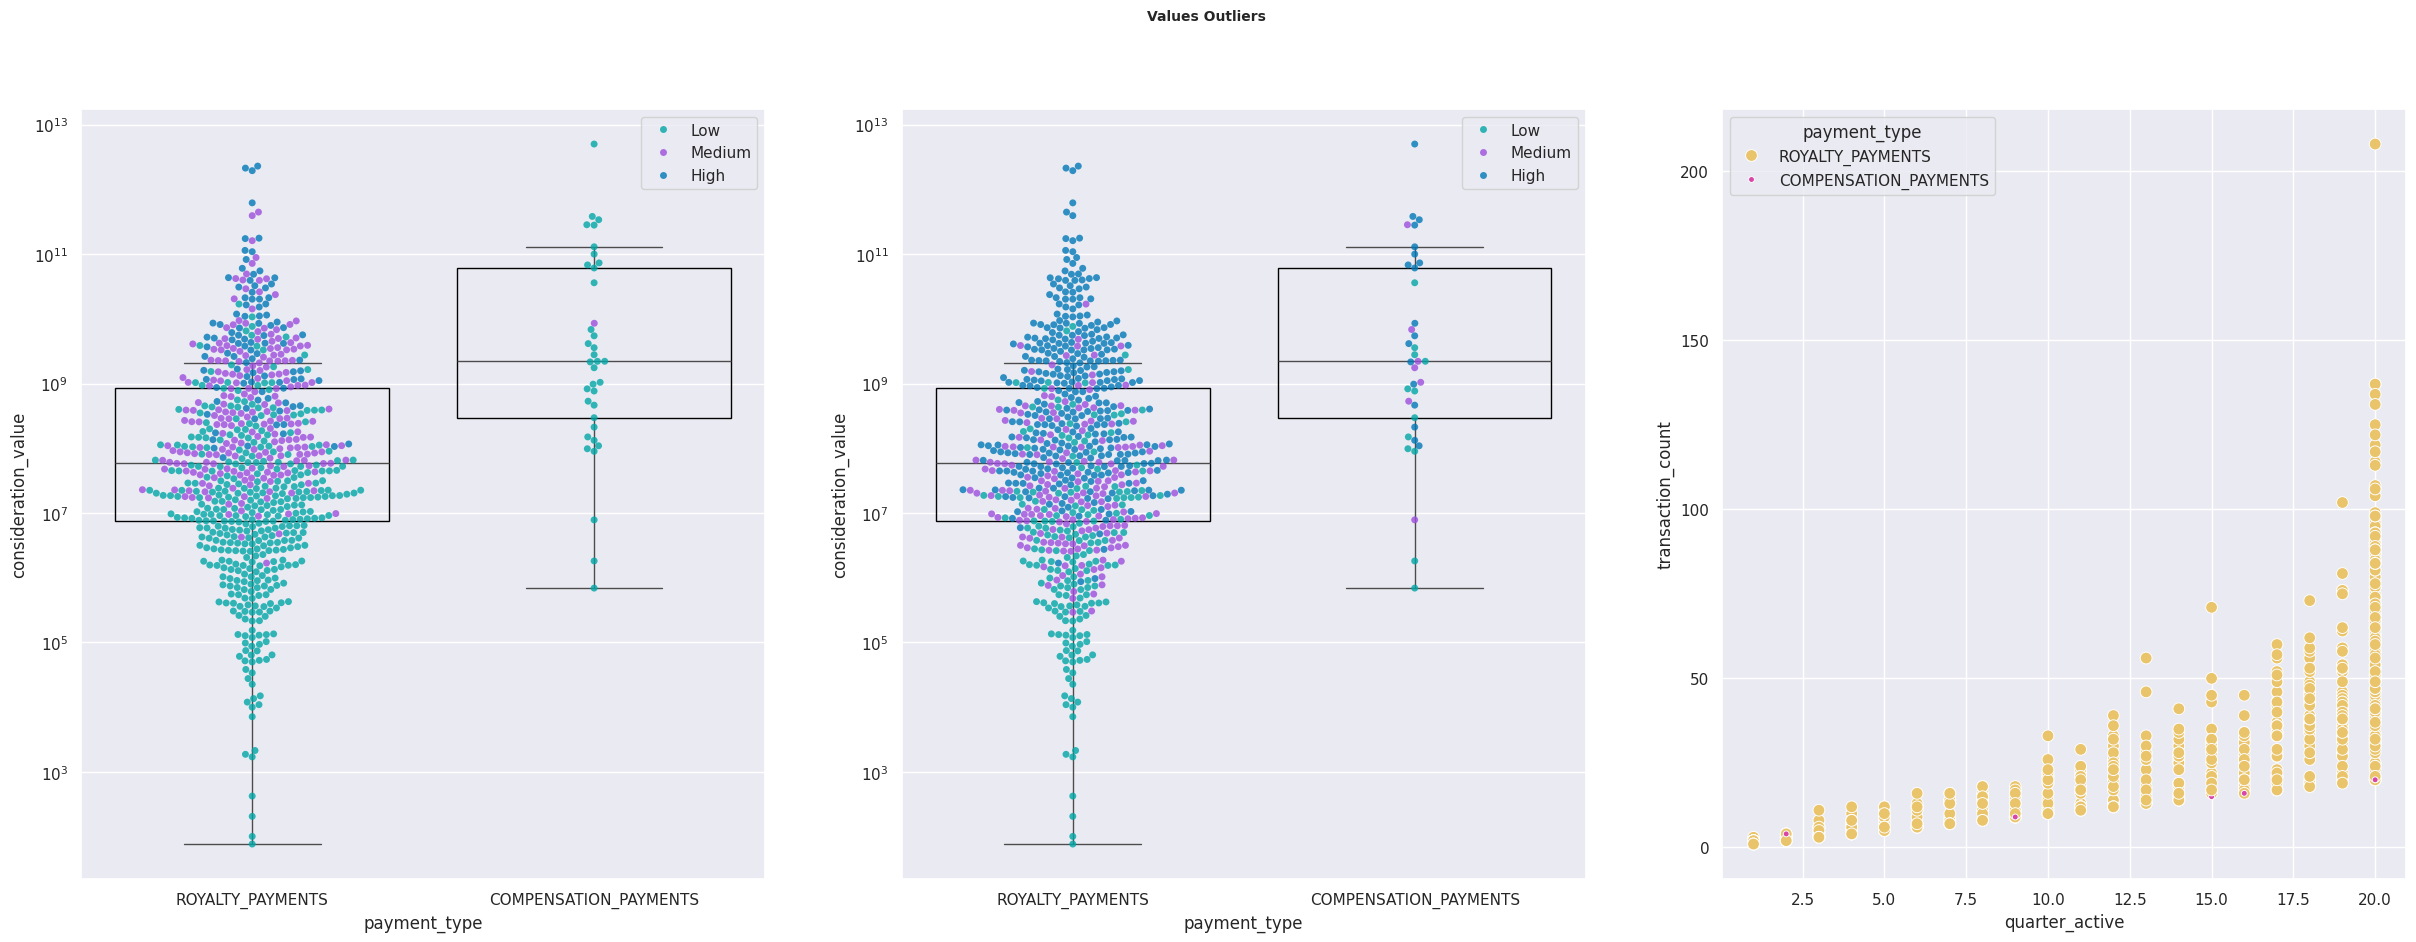

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(30, 10))

sns.swarmplot(
    data=data_group2,
    y="consideration_value",
    x='payment_type',
    ax=ax[0],
    hue='transaction_count_category',
    alpha=0.8,
    palette=paleta
)

sns.boxplot(
    data=data_group2,
    y='consideration_value',
    x='payment_type',
    ax=ax[0],
    boxprops=dict(facecolor='none', edgecolor='black'),
    flierprops=dict(marker=''),
    )
ax[0].set(yscale="log")


sns.swarmplot(
    data=data_group2,
    y="consideration_value",
    x='payment_type',
    ax=ax[1],
    hue='quarter_active_category',
    alpha=0.8,
    palette=paleta
)

sns.boxplot(
    data=data_group2,
    y='consideration_value',
    x='payment_type',
    ax=ax[1],
    boxprops=dict(facecolor='none', edgecolor='black'),
    flierprops=dict(marker=''),
    )
ax[1].set(yscale="log")

sns.scatterplot(
    data= data_group2,
    x="quarter_active",
    y="transaction_count",
    size = 'payment_type',
    ax=ax[2],
    hue='payment_type', palette=paleta)

fig.suptitle('Values Outliers', fontsize = 10, fontweight = "bold");
plt.show()

**Amount by Transaction Category (Left Panel)**

- **Difference in levels:** the compensation box is positioned higher than the royalty box. The royalty median is close to 6 × 10⁷, whereas the compensation median is close to 2 × 10⁹, about `37 times` higher.
- **Greater variability in royalties:** royalty amounts range from values close to 10² to more than 10¹². This indicates substantial heterogeneity in the amounts paid.
- **Extreme observations:** both payment types have observations far from their central distribution. Royalties show many low values and a long upper tail. Among compensation payments, one point close to 5 × 10¹² stands out as the highest value in the entire dataset.
- **Royalty categories:** the Low category is concentrated in the lower part of the distribution, whereas the Medium and High categories extend across different amount levels.
- **Overlap:** although some differences are visible, the categories overlap considerably. The number of transactions does not clearly separate amount levels.
- **Compensation pattern:** compensation payments are much less numerous, but their amounts are generally at higher levels than those of royalties.

**Amount by Active Quarter Category (Center Panel)**

- **Difference in levels:** as in the previous panel, compensation payments have a higher central distribution than royalties.
- **Variability in royalties:** royalties show considerable dispersion, with values ranging from very low to very high.
- **Overlap between categories:** the Low, Medium, and High categories overlap across the distributions. The number of active quarters does not establish a clear distinction between amount levels.
- **Amount and activity:** high amounts are observed across the different activity categories. However, the chart does not show that higher activity causes higher payments or that the amount increases consistently with the number of active quarters.

**Transactions vs. Active Quarters (Right Panel)**

- **Positive association:** the chart shows an upward trend. Municipalities with more active quarters tend to record more transactions. With few active quarters, transactions are low, whereas observations with much higher values appear between 15 and 20 quarters.
- **Possible nonlinear relationship:** the increase in transactions appears more pronounced at high values of quarter_active. This suggests that the relationship may not be strictly linear, although additional statistical analysis would be required to confirm it.
- **Increasing variability:** with 20 active quarters, the number of transactions ranges from approximately 20 to 208. Municipalities with the same duration can have very different levels of transaction activity.
- **Unusual observations:** the point with 208 transactions in 20 quarters is clearly separated from the rest. Compensation payments are located in the lower part of the chart, with 30 transactions or fewer.

**Conclusion:** no single variable separates usual behavior from unusual behavior. This supports the use of a multivariate model that evaluates the three dimensions jointly.

# **Multivariate Anomaly Model**
---

**Why Separate Compensation Payments and Royalties?**

- Compensation payments and royalties represent different financial obligations within the mining sector. Although both are associated with mining activity, they differ in their economic nature, calculation criteria, and payment mechanisms. As a result, their amount distributions show different patterns in scale, variability, and statistical behavior.

- The previous exploration confirms this: the median compensation amount is about 37 times the median royalty amount. If both payment types were analyzed together, the model could flag compensation payments as anomalous only because they belong to another payment type, and not because of unusual behavior within their own group.

- For this reason, an independent model is trained for each payment type. Each group is evaluated according to its own distribution.

In [ ]:
data_group2_regalias = data_group2[data_group2['payment_type'] == 'ROYALTY_PAYMENTS'].copy()
data_group2_compensacion = data_group2[data_group2['payment_type'] == 'COMPENSATION_PAYMENTS'].copy()
data_group2['payment_type'].value_counts()

,count
payment_type,
ROYALTY_PAYMENTS,706
COMPENSATION_PAYMENTS,37


The set of profiles is divided into two groups by payment type:

- **Royalties:** `706` profiles, 95% of the total.
- **Compensation payments:** `37` profiles, 5% of the total.

The difference in size is important for interpreting the results. The royalty model is trained on a large sample, whereas the compensation model has very few records, so each observation carries considerable weight in its result.

---

Two Isolation Forest models are implemented, one for each payment type, with the same configuration:

- **n_estimators = 100:** each model combines 100 isolation trees.
- **contamination = 0.05:** approximately 5% of the records are assumed to be anomalous. This parameter defines the threshold that separates the two classes.
- **max_samples = 'auto':** each tree is trained on min(256, n) records. For compensation payments, each tree uses all 37 records. For royalties, each tree uses a subsample of 256 of the 706 records.
- **bootstrap = False:** the records for each tree are drawn without replacement.
- **random_state:** the seed defined in the configuration is used to obtain reproducible results.

The model isolates each record through random splits on the three variables. Records that are isolated with few splits are considered more anomalous. The hyperparameters were selected arbitrarily.

In [ ]:
model_aoutliers_regalias = IsolationForest(
    n_estimators=100,
    max_samples='auto',
    contamination=0.05,
    bootstrap=False,
    random_state = random_seed,
    verbose=0,
    n_jobs=-1,
)

model_group2_compensacion = IsolationForest(
    n_estimators=100,
    max_samples='auto',
    contamination=0.05,
    bootstrap=False,
    random_state = random_seed,
    verbose=0,
    n_jobs=-1,
)

model_aoutliers_regalias.fit(data_group2_regalias[[
    'consideration_value',
    'transaction_count',
    'quarter_active']])


model_group2_compensacion.fit(data_group2_compensacion[[
    'consideration_value',
    'transaction_count',
    'quarter_active']])

IsolationForest(contamination=0.05, n_jobs=-1, random_state=12354)

The output corresponds to the last model trained, the compensation model, and confirms that training was completed. The representation only shows the parameters that differ from the default values: contamination=0.05, n_jobs=-1, and random_state=12354. The other configured parameters (100 trees, max_samples='auto', and bootstrap=False) match the scikit-learn default values.

Both models were trained on the three numeric profile variables: consideration_value, transaction_count, and quarter_active. The Jenks categories were not included in training.

The models are applied to the same data used for training, following an unsupervised approach. The predict() method assigns a label to each record, which is stored in the aoutliers column:

- **-1:** anomalous record.
- **1:** normal record.

The royalty model is applied first.

In [ ]:
y_predict = model_aoutliers_regalias.predict(X=data_group2_regalias[[
    'consideration_value',
    'transaction_count',
    'quarter_active']])
data_group2_regalias['aoutliers'] = y_predict

The number of royalty records in each class is counted.

In [ ]:
data_group2_regalias['aoutliers'].value_counts()

,count
aoutliers,
1,670
-1,36


The royalty model identified `36 anomalies` among the 706 profiles, that is, 5.1% of the group, and 670 normal records. This proportion matches the contamination parameter of 5%, since the model threshold is set to separate that fraction of the data.

In the next cell, the aoutliers column is converted to text. This conversion allows Plotly to treat the labels as categories and assign the palette colors: reddish orange for -1 and green for 1.

In [ ]:
data_group2_regalias['aoutliers'] = data_group2_regalias['aoutliers'].astype(str)

The same procedure is applied to the compensation model: the labels are predicted, stored in the aoutliers column, and the number of records in each class is counted.

In [ ]:
y_predict = model_group2_compensacion.predict(X=data_group2_compensacion[[
    'consideration_value',
    'transaction_count',
    'quarter_active']])
data_group2_compensacion['aoutliers'] = y_predict

In [ ]:
data_group2_compensacion['aoutliers'].value_counts()

,count
aoutliers,
1,35
-1,2


The compensation model identified `2 anomalies` among the 37 profiles, that is, 5.4% of the group, and 35 normal records. With only 37 records, 5% is equivalent to 1.85 observations, so the number of anomalies is largely determined by the contamination parameter.

As with royalties, the aoutliers column is converted to text in the next cell for use in the charts.

In [ ]:
data_group2_compensacion['aoutliers'] = data_group2_compensacion['aoutliers'].astype(str)

The results of both models are concatenated into the data_merge DataFrame, which combines the 743 profiles with their labels. This DataFrame makes it possible to compare both payment types in the same chart.

In [ ]:
data_merge = pd.concat([data_group2_regalias, data_group2_compensacion], axis=0)
data_merge

,key,payment_type,consideration_value,transaction_count,quarter_active,transaction_count_category,quarter_active_category,aoutliers
0,Abejorral-Antioquia,ROYALTY_PAYMENTS,"52,580,674.00",17,11,Low,Medium,1
1,Abrego-Norte de Santander,ROYALTY_PAYMENTS,"22,530,021.00",21,16,Low,High,1
2,Abriaqui-Antioquia,ROYALTY_PAYMENTS,"355,266,722.00",35,15,Medium,Medium,1
3,Acacias-Meta,ROYALTY_PAYMENTS,"607,849,192.00",58,20,Medium,High,1
4,Achi-Bolivar,ROYALTY_PAYMENTS,"557,468,046.00",6,3,Low,Low,1
...,...,...,...,...,...,...,...,...
656,Tibasosa-Boyaca,COMPENSATION_PAYMENTS,"212,059,238.00",21,20,Low,High,1
716,Villanueva - Santander-Santander,COMPENSATION_PAYMENTS,"976,911,933.00",16,16,Low,High,1
732,Yumbo-Valle del Cauca,COMPENSATION_PAYMENTS,"109,142,566.00",20,20,Low,High,1
735,Zapatoca-Santander,COMPENSATION_PAYMENTS,"1,043,404,222.00",9,9,Low,Medium,1


The table confirms that data_merge contains `743 rows` and 8 columns: key, payment_type, the three model variables, the two Jenks categories, and the aoutliers label. The first rows correspond to royalties and the last rows to compensation payments, such as Tibasosa (Boyaca), Yumbo (Valle del Cauca), and Zipaquira (Cundinamarca).

The records visible in the table are classified as normal (1). For example, Achi (Bolivar) has a high amount for its short activity (557.5 million in 3 quarters), but the model does not consider it anomalous. In the next cell, the aoutliers column is converted to text again to ensure that it is used as a category in the chart.

In [ ]:
data_merge['aoutliers'] = data_merge['aoutliers'].astype(str)

A 3D chart of the 743 profiles is presented. The color indicates the model classification (green for normal and reddish orange for anomaly), and the symbol indicates the payment type (circles for royalties and diamonds for compensation payments). The axes are the same as in the exploratory chart: total amount, number of transactions, and active quarters.

Each payment type was modeled independently. Therefore, the color identifies anomalies relative to their own reference group rather than to the entire dataset.

In [ ]:
fig = plot_3d_scatter(
    data=data_merge,
    x="consideration_value",
    y="transaction_count",
    z="quarter_active",
    color = 'aoutliers',
    color_map = paleta,
    title="Royalty and compensation payments",
    symbol = 'payment_type'
)

**General Observations**

- **Concentration of royalties:** a dense concentration of green circles is visible near the origin, which corresponds to the usual behavior of royalties.
- **Shift of compensation payments:** the compensation diamonds are shifted toward higher amounts. The median compensation amount is about 37 times the median royalty amount, and 34 of the 37 compensation payments exceed the royalty median.

**The Two Anomalous Compensation Payments**

- **Extreme amount record:** one diamond is located at the end of the amount axis, with `4.997 × 10¹²` in 22 transactions and 20 quarters. It is the observation farthest from the origin in the entire chart.
- **High-frequency record:** the other diamond has an amount of 8.52 × 10⁹, much closer to the origin, but it records 30 transactions, the maximum among compensation payments.

The extreme amount record deserves special attention:

- Its amount exceeds the highest royalty (2.28 × 10¹²) and even the sum of the two highest royalties (4.40 × 10¹²).
- It reaches this amount with 22 transactions, fewer than the three highest royalties, which record 95, 208, and 137 transactions.
- Its average amount per transaction is about 2.27 × 10¹¹, close to 10 times that of the highest royalty (2.4 × 10¹⁰) and about 86,000 times the median royalty amount per transaction (2.64 × 10⁶).
- Its amount is 13.1 times that of the second-highest compensation payment.
- By itself, it represents `73.6%` of the total value of compensation payments and is equivalent to 49% of the total value of royalties.

**Royalty Anomalies**

Several marginal anomalies appear among royalties, close to normal records. The most distant anomalies correspond to three profiles with amounts above 10¹² and a high number of transactions, as detailed in the next chart.

---

The 3D chart is presented with royalty profiles only, colored by the model classification. When compensation payments are excluded, the scale adjusts to this group, which makes it easier to observe the position of the 36 anomalies relative to the 670 normal records.

In [ ]:
fig = plot_3d_scatter(
    data=data_group2_regalias,
    x="consideration_value",
    y="transaction_count",
    z="quarter_active",
    color = 'aoutliers',
    color_map = paleta,
    title="Royalty payments",
)

The green points are grouped near the origin. The normal records have a median of about 50 million, 22 transactions, and 14 active quarters, and their highest amount does not exceed 4.9 × 10¹⁰. As the number of active quarters increases, more transactions are observed, so the cloud extends in an orderly way along those two axes.

The anomalies, which represent 5% of the royalty records, account for `89%` of the total amount paid (9.1 × 10¹² out of 10.2 × 10¹²). This is a strong concentration: a few municipalities explain most of the amount, and the three largest account for about 62%.

**Direction of the anomalies:** all anomalies have an amount equal to or greater than 2.3 × 10⁸, above the median of the normal records. No low-amount record was classified as anomalous, even though values as small as 77 exist. In this dataset, the model mainly identifies the upper end of the distribution.

**Value of the multivariate approach:** among the anomalies, there are records with moderate amounts, such as 2.4 × 10⁸ with only 4 transactions in 2 quarters. Among the normal records, there are high amounts of up to 4.9 × 10¹⁰. A criterion based only on the amount would have excluded the former and included the latter. In these cases, the anomaly arises because the three variables do not maintain their usual proportion.

---

The 3D chart is presented with compensation profiles only. With 37 records, this is the smallest group, so each point carries considerable weight in the interpretation of the chart.

In [ ]:
fig = plot_3d_scatter(
    data=data_group2_compensacion,
    x="consideration_value",
    y="transaction_count",
    z="quarter_active",
    color = 'aoutliers',
    color_map = paleta,
    title="Compensation payments",
)

The compensation group includes 37 records: 35 normal (green) and 2 anomalous (reddish orange). The normal records have a median of about 2.16 billion, 16 transactions, and 15 active quarters. Their highest amount is 3.8 × 10¹¹.

Two characteristics distinguish the group:

- **Few transactions:** no normal record exceeds 21 transactions, and 15 of the 37 records have 10 or fewer. This is a group of infrequent payments.
- **High amounts per transaction:** the median amount per transaction is about 2.1 × 10⁸, roughly `78 times` that of royalties (2.6 × 10⁶).

In summary, compensation payments are few, are made infrequently, and each payment is large. Thirteen of the 37 records exceed the 90th percentile of the total royalty amount.

| Record | Amount | Transactions | Quarters | Why it stands out |
|---|---|---|---|---|
| A | 4.997 × 10¹² | 22 | 20 | Amount 13 times higher than the next one and higher than any royalty |
| B | 8.52 × 10⁹ | 30 | 20 | Highest number of transactions in the group, with an intermediate amount |

**Record A** is the central case. Its amount is 13 times the next one and accounts for 73.6% of the group's total value. However, its number of transactions (22) is similar to that of a typical compensation payment. This defines its profile: **few payments of disproportionate size**.

**Record B** deviates from the group in the opposite direction: its amount is intermediate, but its payment frequency is higher than that of any other compensation payment.

---

- To analyze the behavior of royalty records in more detail, the anomaly score of each record is calculated with the trained model. The three model variables are considered: the consideration value (consideration_value), the number of transactions (transaction_count), and the number of active quarters (quarter_active).

- The score_samples() method assigns an individual score to each record. Unlike predict(), which only returns the -1 and 1 classes, the score makes it possible to rank records by their degree of anomaly and to examine where the classification threshold is located.

In [ ]:
score_anomalia  = model_aoutliers_regalias.score_samples(
    X=data_group2_regalias[[
        'consideration_value',
        'transaction_count',
        'quarter_active']])

- The score is a continuous indicator of the degree of anomaly. The more negative the score, the more anomalous the record is considered, because it was isolated with fewer splits in the model trees. The first 50 scores are displayed to review their scale.

In [ ]:
score_anomalia[:50]

array([-0.403, -0.391, -0.416, -0.403, -0.535, -0.393, -0.435, -0.434,
       -0.403, -0.418, -0.732, -0.416, -0.409, -0.764, -0.451, -0.418,
       -0.489, -0.48 , -0.448, -0.425, -0.414, -0.45 , -0.399, -0.405,
       -0.449, -0.471, -0.43 , -0.439, -0.4  , -0.418, -0.413, -0.486,
       -0.416, -0.412, -0.399, -0.402, -0.435, -0.395, -0.398, -0.438,
       -0.448, -0.432, -0.391, -0.422, -0.432, -0.442, -0.399, -0.416,
       -0.405, -0.453])

The first 50 scores range from `-0.764` to `-0.391`, with a median of -0.418. Most scores are concentrated between -0.39 and -0.45, which corresponds to usual behavior.

Two values stand out far from the rest. Based on the order of the records in data_group2_regalias:

- **-0.764** (record 14 in the array): corresponds to a profile with an amount of 6.17 × 10¹¹, 137 transactions, and 20 active quarters.
- **-0.732** (record 11 in the array): corresponds to a profile with an amount of 4.45 × 10¹¹, 37 transactions, and 17 active quarters.

Record 5 in the array, Achi (Bolivar), has a score of -0.535. Its amount is high for its short activity (557.5 million in 6 transactions and 3 quarters), but its score is just above the model threshold (-0.538, calculated later), so it is classified as normal. This case shows that some records are located very close to the boundary between the two classes.

---

- An alternative threshold is set arbitrarily using the 3rd percentile (0.03 quantile) of the anomaly score distribution.
- This value serves as a stricter cutoff point than the model threshold. Since more negative scores indicate a higher degree of anomaly, records with a score below this threshold are considered the clearest anomaly candidates.

In [ ]:
p_arbitrary = np.quantile(score_anomalia, q=0.03)
p_arbitrary

np.float64(-0.5777606654686601)

The 3rd percentile of the royalty scores is `-0.578`. By definition, about 3% of the records, approximately 21 of the 706, have a score below this value. These records form the core of the most severe anomalies in the group.

---

A second threshold is calculated based on the contamination parameter of the model. To do so, the 0.05 quantile of the anomaly score distribution is obtained, which corresponds to the contamination proportion defined in the configuration.

In [ ]:
p_contamination_model = np.quantile(score_anomalia, q=model_aoutliers_regalias.contamination)
p_contamination_model

np.float64(-0.5383150012420285)

The contamination quantile of the royalty scores is `-0.538`. This threshold is less strict than the 3rd percentile (-0.578) because it includes 5% of the records instead of 3%. Approximately 15 records fall between the two thresholds and can be considered marginal anomalies.

---

The offset_ attribute represents the internal threshold that the Isolation Forest model uses to separate normal records from anomalous ones. Records with a score below offset_ receive the -1 label in predict(). This value is retrieved to compare it with the contamination quantile calculated in the previous cell.

In [ ]:
model_aoutliers_regalias.offset_

np.float64(-0.5383150012420285)

The value of offset_ is `-0.538`, exactly equal to the contamination quantile calculated earlier. This confirms that the model threshold is not derived from a natural separation in the data. Instead, it is set so that 5% of the training records fall below it. For this reason, the royalty model classified 36 records as anomalous, 5.1% of the group.

---

The distribution of the royalty anomaly scores is presented using two elements:

- **Density curve (KDE):** shows where the scores are concentrated.
- **Rug plot:** each vertical mark on the horizontal axis represents one record.

The two calculated thresholds are drawn over the distribution:

- **Red line:** model threshold (offset_), based on a contamination level of 5%.
- **Orange line:** arbitrary 3rd percentile threshold.

The objective is to observe how the scores are distributed and which records fall below each threshold.

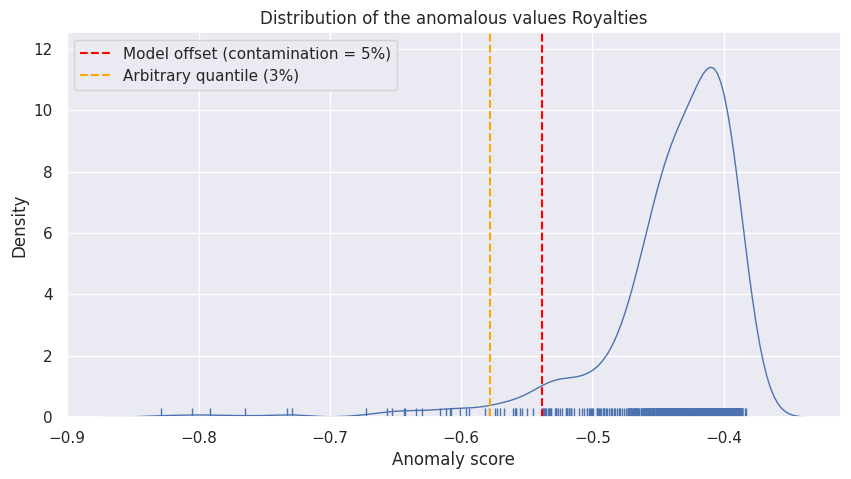

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))
sns.kdeplot(
    score_anomalia,
    fill    = False,
    color   = 'b',
    linewidth = 1,
    ax      = ax
)
sns.rugplot(score_anomalia, color='b', ax=ax)

ax.axvline(model_aoutliers_regalias.offset_, c='red', linestyle='--',
           label='Model offset (contamination = 5%)')
ax.axvline(p_arbitrary, c='orange', linestyle='--',
           label='Arbitrary quantile (3%)')
ax.set_title('Distribution of the anomalous values Royalties')
ax.set_xlabel('Anomaly score')
plt.legend()
plt.show()

**Chart Interpretation**

- **Axes:** the horizontal axis represents the anomaly score, from approximately -0.9 to -0.35. The vertical axis represents the estimated density of records.
- **Main concentration:** most records are concentrated in a sharp peak near `-0.41`, with a maximum density above 11. This area corresponds to the usual behavior of royalties.
- **Shoulder near -0.52:** to the left of the peak, the curve forms a small shoulder just before the model threshold. Records in this area begin to deviate from the general pattern.
- **Left tail:** from -0.55, the density drops almost to zero, but the rug plot shows scattered records down to approximately `-0.83`. Several of them are located between -0.83 and -0.73, separated from the rest.

**Threshold Comparison**

- **Model threshold (red, -0.538):** separates the 36 anomalies. It includes both the records in the far tail and the records close to the transition area.
- **3rd percentile threshold (orange, -0.578):** is stricter and leaves approximately 21 records below it, the most distant ones.
- **Area between the two lines:** contains the marginal anomalies, which are closer to usual behavior.

**Interpretation**

The anomalies are located in the left tail, where the density of records is low. Their characteristics, in terms of amount, transactions, and active quarters, deviate from the predominant behavior of royalties.

The distribution does not show a natural separation at the position of the model threshold: the curve decreases continuously between the peak and the tail. For this reason, the boundary between normal records and marginal anomalies depends on the contamination parameter. The records in the far tail, in contrast, show a clear separation and are the priority cases for review.

---

- The score analysis is repeated with the compensation model. The same three variables are considered: the consideration value (consideration_value), the number of transactions (transaction_count), and the active quarters (quarter_active).

- The score_samples() method assigns an individual anomaly score to each of the 37 records.

In [ ]:
score_anomalia  = model_group2_compensacion.score_samples(
    X=data_group2_compensacion[[
    'consideration_value',
    'transaction_count',
    'quarter_active']])

- The more negative the score, the more anomalous the record is considered. Since the compensation group contains 37 records, requesting the first 50 scores displays all of them.

In [ ]:
score_anomalia[:50]

array([-0.544, -0.488, -0.505, -0.749, -0.438, -0.456, -0.506, -0.528,
       -0.372, -0.492, -0.449, -0.471, -0.437, -0.451, -0.496, -0.499,
       -0.494, -0.41 , -0.622, -0.565, -0.416, -0.458, -0.465, -0.402,
       -0.476, -0.493, -0.473, -0.381, -0.374, -0.376, -0.454, -0.467,
       -0.408, -0.447, -0.372, -0.459, -0.487])

The 37 scores range from `-0.749` to `-0.372`, with a median of -0.465. Based on the order of the records in data_group2_compensacion, the most negative scores correspond to:

| Score | Amount | Transactions | Quarters | Interpretation |
|---|---|---|---|---|
| -0.749 | 4.997 × 10¹² | 22 | 20 | Record A, the extreme amount record |
| -0.622 | 8.52 × 10⁹ | 30 | 20 | Record B, the highest-frequency record |
| -0.565 | 3.60 × 10¹⁰ | 7 | 7 | First normal record |
| -0.544 | 3.81 × 10¹¹ | 17 | 17 | Highest normal amount |

Record A has the most negative score and is clearly separated from the rest. Record B ranks second, with a smaller distance from the normal records. The least negative scores (-0.372 and -0.374) correspond to records with 20 transactions in 20 quarters, the most common pattern in the group.

- The arbitrary 3rd percentile threshold is calculated on the compensation scores, using the same criterion applied to royalties.

In [ ]:
p_arbitrary = np.quantile(score_anomalia, q=0.03)
p_arbitrary

np.float64(-0.6176325241414379)

The 3rd percentile of the compensation scores is `-0.618`. With 37 records, 3% is equivalent to slightly more than one observation. Two records have a score below this value: record A (-0.749) and record B (-0.622).

The internal threshold of the compensation model (offset_), which separates normal records from anomalous ones, is retrieved.

In [ ]:
model_group2_compensacion.offset_

np.float64(-0.5766833937132589)

The value of offset_ is `-0.577`. The two records with lower scores, A and B, are the same records that the model classified as anomalous. The first normal record has a score of -0.565, only 0.012 from the threshold.

The contamination quantile is calculated on the compensation scores to compare it with offset_.

In [ ]:
p_contamination_model = np.quantile(score_anomalia, q=model_group2_compensacion.contamination)
p_contamination_model

np.float64(-0.5766833937132589)

The contamination quantile is `-0.577`, equal to the value of offset_. As in the royalty model, this confirms that the model threshold corresponds to the 0.05 quantile of the training scores.

The distribution of the compensation anomaly scores is presented with the same structure as the royalty chart: density curve (KDE), rug plot with one mark per record, model threshold in red, and 3rd percentile threshold in orange.

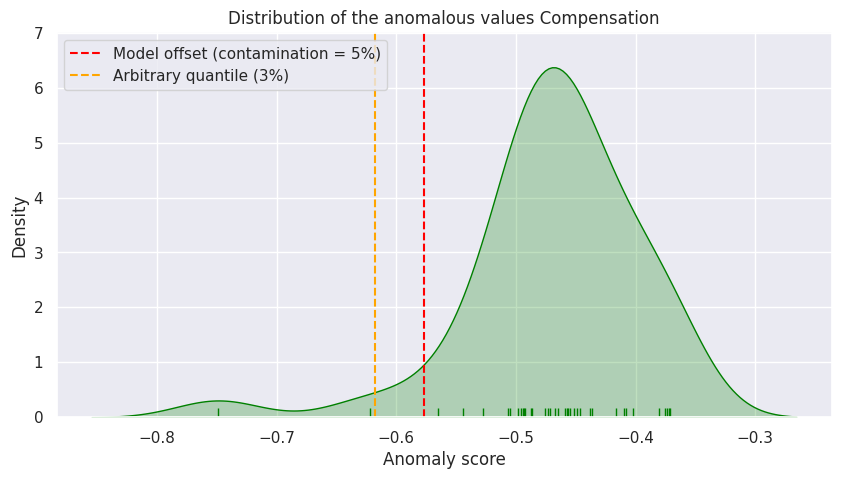

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))
sns.kdeplot(
    score_anomalia,
    fill    = True,
    color   = 'green',
    linewidth = 1,
    ax      = ax
)
sns.rugplot(score_anomalia, color='green', ax=ax)

ax.axvline(model_group2_compensacion.offset_, c='red', linestyle='--',
           label='Model offset (contamination = 5%)')
ax.axvline(p_arbitrary, c='orange', linestyle='--',
           label='Arbitrary quantile (3%)')
ax.set_title('Distribution of the anomalous values Compensation')
ax.set_xlabel('Anomaly score')
plt.legend()
plt.show()

**Chart Interpretation**

- **Axes:** the horizontal axis represents the anomaly score, and the vertical axis represents the estimated density. The 37 scores range from -0.75 to -0.37.
- **Main concentration:** most records are concentrated around `-0.47`, with a maximum density close to 6.4.
- **Secondary bump near -0.75:** it corresponds to a single observation, record A. Its shape results from the smoothing of the density curve, not from a group of records.

**Threshold Comparison**

- **Model threshold (red, -0.577) and 3rd percentile threshold (orange, -0.618):** both identify the same two records, A (-0.749) and B (-0.622). No record is located between the two lines. With 37 records, 3% is equivalent to slightly more than one observation and 5% to almost two, which explains this agreement.

**Strength of the Two Anomalies**

- **Record A:** is clearly separated from the main group. It provides the strongest evidence of anomalous behavior among compensation payments.
- **Record B:** is close to the boundary, 0.045 below the model threshold. The closest normal records have scores of -0.565 and -0.544. A higher contamination level may include these records and change the set of anomalies.

**Comparison with Royalties**

The compensation scores are generally more negative than the royalty scores, whose peak is located near -0.41. These values are not directly comparable, because each model was fitted independently and the score scale depends on its training data.

**Conclusion:** the model flags approximately 5% of the records by construction, and the contamination level was selected arbitrarily. Therefore, the two records should be reviewed with different priority: record A as a priority case and record B as a marginal case.

# **Conclusions**
---
- **Approach:** a five-year profile (2018 to 2022) was built for each municipality and payment type, with three variables: total amount, number of transactions, and active quarters. An independent Isolation Forest model was trained for royalties (706 profiles) and for compensation payments (37 profiles) because their scales are very different.

- **Royalties:** `36 anomalies` were identified. These records account for 89% of the total amount paid and mainly correspond to municipalities with very high amounts, activity in all 20 quarters, or a high number of transactions. The model mainly identifies the upper end of the distribution: no low-amount record was classified as anomalous.

- **Compensation payments:** `2 anomalies` were identified. Record A, with 4.997 × 10¹², accounts for 73.6% of the group's value and is the clearest case in the entire analysis. Record B stands out for its payment frequency and is located close to the threshold.

- **Thresholds:** in both models, the internal threshold (offset_) matches the contamination quantile. Therefore, the number of anomalies depends on the contamination parameter, which was set arbitrarily at 5%. The arbitrary percentile, in this case the 3rd percentile, provides a stricter criterion to prioritize the most distant cases.

# **Info**
---
**@By**: Steven Bernal

**@Nickname:** Kaiziferr

**@Git**: https://github.com/Kaiziferr